In [ ]:
import torch
import torch.nn as nn

class PINN(nn.Module):
    def __init__(self):
        super().__init__()
        # A simple 3-layer network
        self.net = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(), # Tanh is preferred over ReLU in PINNs because its 2nd derivative is non-zero
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, t):
        return self.net(t)

In [ ]:
# Generate 100 random time points between t=0 and t=10
t_physics = torch.rand(100, 1) * 10.0
t_physics.requires_grad = True # CRITICAL: We need gradients with respect to the input!

In [ ]:
def physics_loss(model, t, k=0.1):
    # 1. Get the model's prediction for temperature T
    T = model(t)

    # 2. Calculate the derivative dT/dt using autograd
    dT_dt = torch.autograd.grad(
        T, t,
        grad_outputs=torch.ones_like(T),
        create_graph=True # Required to backpropagate through the derivative
    )[0]

    # 3. Define the physics equation (Residual should be 0)
    # If dT/dt = -kT, then the residual is dT/dt + kT
    residual = dT_dt + k * T

    # 4. The loss is the Mean Squared Error of the residual
    return torch.mean(residual**2)

In [ ]:
def boundary_loss(model):
    t_0 = torch.tensor([[0.0]])
    T_0_prediction = model(t_0)
    T_0_true = torch.tensor([[100.0]])
    return torch.mean((T_0_prediction - T_0_true)**2)

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(5000):
    optimizer.zero_grad()

    loss_p = physics_loss(model, t_physics)
    loss_b = boundary_loss(model)

    total_loss = loss_p + loss_b
    total_loss.backward()
    optimizer.step()

Heat Code

In [ ]:
import torch
import torch.nn as nn

# Generate 5000 random (x, t) coordinates.
# requires_grad=True is critical so PyTorch tracks derivatives back to the inputs
num_points = 5000
L = 2.0      # Rod length
T_max = 1.0  # Max simulation time

x_physics = torch.rand(num_points, 1, requires_grad=True) * L
t_physics = torch.rand(num_points, 1, requires_grad=True) * T_max

In [ ]:
class HeatPINN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

    def forward(self, x, t):
        # Concatenate x and t into a single input array
        inputs = torch.cat([x, t], dim=1)
        return self.net(inputs)

In [ ]:
def physics_loss(model, x, t, alpha=0.05):
    # 1. Predict temperature
    u = model(x, t)

    # 2. Calculate first derivatives (du/dt and du/dx)
    du_dt = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    du_dx = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]

    # 3. Calculate second derivative (d^2u/dx^2) by taking the derivative of du_dx
    d2u_dx2 = torch.autograd.grad(du_dx, x, grad_outputs=torch.ones_like(du_dx), create_graph=True)[0]

    # 4. The Heat Equation Residual: du/dt - alpha * d^2u/dx^2 = 0
    residual = du_dt - alpha * d2u_dx2

    # 5. Minimize the mean squared error of the residual
    return torch.mean(residual**2)

In [ ]:
def initial_condition_loss(model, num_points=500):
    # 1. Generate random x points across the 2-meter rod
    x_ic = torch.rand(num_points, 1) * 2.0

    # 2. Clamp the time coordinate strictly to t = 0
    t_ic = torch.zeros_like(x_ic)

    # 3. Define the true initial temperature (a sharp Gaussian peak at x = 1.0)
    # u(x, 0) = exp(-(x - 1.0)^2 / 0.1)
    u_true = torch.exp(-((x_ic - 1.0)**2) / 0.1)

    # 4. Get model predictions and compute Mean Squared Error
    u_pred = model(x_ic, t_ic)
    return torch.mean((u_pred - u_true)**2)

In [ ]:
def boundary_condition_loss(model, num_points=500):
    # 1. Generate random time points up to T_max = 1.0
    t_bc = torch.rand(num_points, 1) * 1.0

    # 2. Left boundary constraint: x = 0
    x_left = torch.zeros_like(t_bc)
    u_left_pred = model(x_left, t_bc)
    loss_left = torch.mean(u_left_pred**2)  # Target is u = 0, so MSE is just prediction^2

    # 3. Right boundary constraint: x = 2.0
    x_right = torch.ones_like(t_bc) * 2.0
    u_right_pred = model(x_right, t_bc)
    loss_right = torch.mean(u_right_pred**2) # Target is u = 0

    return loss_left + loss_right

In [ ]:
# Initialize the network and optimizer
model = HeatPINN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Define simulation constants
epochs = 10000
L = 2.0
T_max = 1.0
num_collocation_points = 5000

for epoch in range(epochs):
    optimizer.zero_grad()

    # 1. Generate fresh collocation points for the physics loss every epoch
    # This prevents the network from just memorizing a static grid
    x_physics = torch.rand(num_collocation_points, 1, requires_grad=True) * L
    t_physics = torch.rand(num_collocation_points, 1, requires_grad=True) * T_max

    # 2. Compute the three loss components
    loss_p = physics_loss(model, x_physics, t_physics, alpha=0.05)
    loss_ic = initial_condition_loss(model)
    loss_bc = boundary_condition_loss(model)

    # 3. Combine and backpropagate
    total_loss = loss_p + loss_ic + loss_bc
    total_loss.backward()

    optimizer.step()

    # Optional: Log progress
    if epoch % 1000 == 0:
        print(f"Epoch {epoch} | Total: {total_loss.item():.4f} "
              f"| Physics: {loss_p.item():.4f} | IC: {loss_ic.item():.4f} | BC: {loss_bc.item():.4f}")

Epoch 0 | Total: 0.2598 | Physics: 0.0028 | IC: 0.1081 | BC: 0.1489
Epoch 1000 | Total: 0.0015 | Physics: 0.0010 | IC: 0.0004 | BC: 0.0000
Epoch 2000 | Total: 0.0003 | Physics: 0.0002 | IC: 0.0000 | BC: 0.0000
Epoch 3000 | Total: 0.0001 | Physics: 0.0001 | IC: 0.0000 | BC: 0.0000
Epoch 4000 | Total: 0.0001 | Physics: 0.0001 | IC: 0.0000 | BC: 0.0000
Epoch 5000 | Total: 0.0001 | Physics: 0.0000 | IC: 0.0000 | BC: 0.0000
Epoch 6000 | Total: 0.0001 | Physics: 0.0000 | IC: 0.0000 | BC: 0.0000
Epoch 7000 | Total: 0.0001 | Physics: 0.0000 | IC: 0.0000 | BC: 0.0000
Epoch 8000 | Total: 0.0000 | Physics: 0.0000 | IC: 0.0000 | BC: 0.0000
Epoch 9000 | Total: 0.0000 | Physics: 0.0000 | IC: 0.0000 | BC: 0.0000


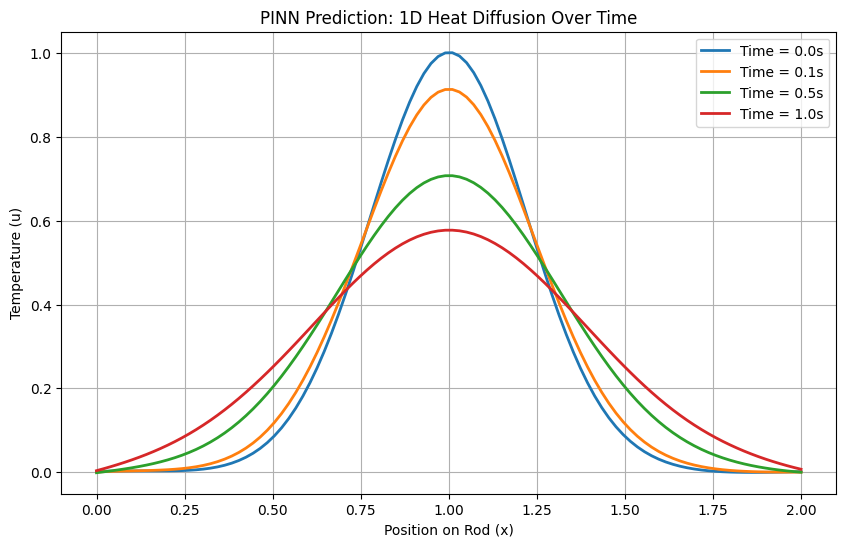

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# 1. Set the model to evaluation mode (disables dropout/batchnorm if used)
model.eval()

# 2. Create a dense array of 100 points along the 2-meter rod
# .view(-1, 1) ensures it is a column vector of shape [100, 1]
x_vals = torch.linspace(0, 2.0, 100).view(-1, 1)

time_steps = [0.0, 0.1, 0.5, 1.0]

plt.figure(figsize=(10, 6))

# 3. Disable gradient tracking since we are just doing inference (saves memory and speeds up execution)
with torch.no_grad():
    for t_val in time_steps:
        # Create a time tensor filled with the current time step, matching the shape of x_vals
        t_tensor = torch.ones_like(x_vals) * t_val

        # Pass the space and time coordinates to the model
        u_pred = model(x_vals, t_tensor)

        # Plot the predictions (convert back to numpy arrays for matplotlib)
        plt.plot(x_vals.numpy(), u_pred.numpy(), label=f'Time = {t_val}s', linewidth=2)

plt.title("PINN Prediction: 1D Heat Diffusion Over Time")
plt.xlabel("Position on Rod (x)")
plt.ylabel("Temperature (u)")
plt.legend()
plt.grid(True)
plt.show()

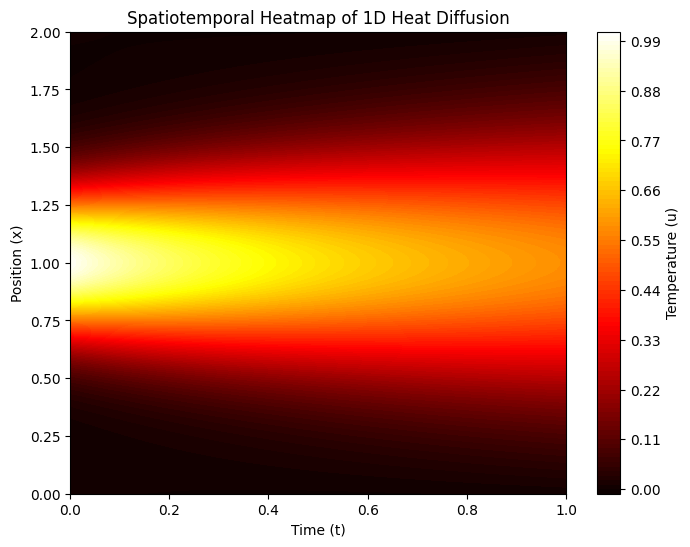

In [ ]:
# 1. Create 100 points for both space (x) and time (t)
x_vals = torch.linspace(0, 2.0, 100)
t_vals = torch.linspace(0, 1.0, 100)

# 2. Create a 2D meshgrid from these points
X, T = torch.meshgrid(x_vals, t_vals, indexing='ij')

# 3. Flatten the grids into column vectors so the neural network can process them
# Shape becomes [10000, 1]
x_flat = X.reshape(-1, 1)
t_flat = T.reshape(-1, 1)

with torch.no_grad():
    # 4. Predict the temperature for all 10,000 coordinate pairs simultaneously
    u_flat_pred = model(x_flat, t_flat)

# 5. Reshape the flat 1D predictions back into the 100x100 2D grid shape
U_pred = u_flat_pred.reshape(X.shape)

# 6. Plot the heatmap
plt.figure(figsize=(8, 6))
contour = plt.contourf(T.numpy(), X.numpy(), U_pred.numpy(), levels=100, cmap='hot')
plt.colorbar(contour, label='Temperature (u)')

plt.title("Spatiotemporal Heatmap of 1D Heat Diffusion")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.show()

Comparision Code

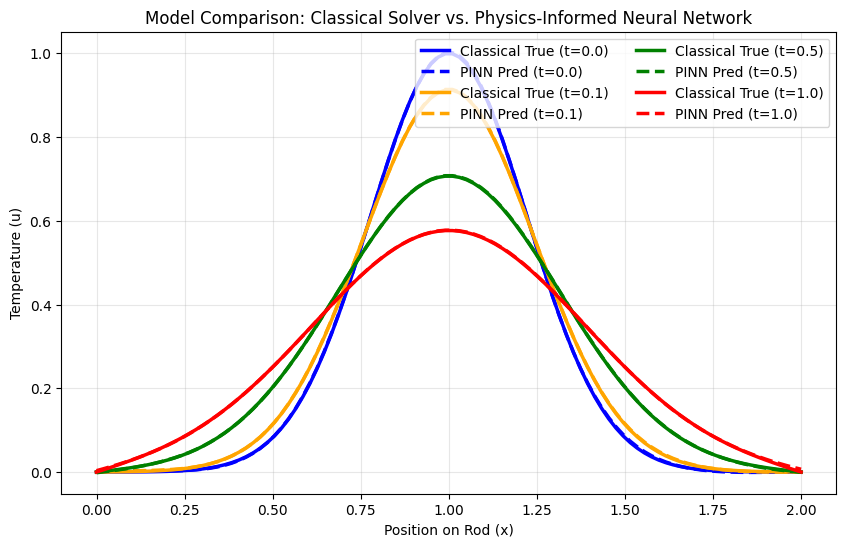

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

# --- 1. Classical Finite Difference Method (Ground Truth) ---
L = 2.0
T_max = 1.0
alpha = 0.05

# Discretize the grid (The traditional "Mesh")
nx = 100
dx = L / (nx - 1)
x_fdm = np.linspace(0, L, nx)

# To remain mathematically stable, the classical method forces us to take
# incredibly tiny time steps (The CFL Condition). PINNs don't have this restriction!
dt = (dx**2) / (4 * alpha)
nt = int(T_max / dt) + 1

u_fdm = np.zeros(nx)

# Apply Initial Condition
u_fdm = np.exp(-((x_fdm - 1.0)**2) / 0.1)

time_steps_to_plot = [0.0, 0.1, 0.5, 1.0]
true_solutions = {}

# Run the classical simulation frame-by-frame
current_time = 0.0
for n in range(nt):
    # Save the array if we cross a target time step
    for t_plot in time_steps_to_plot:
        if abs(current_time - t_plot) < dt / 2:
            true_solutions[t_plot] = u_fdm.copy()

    # Calculate spatial curvature and step forward in time
    u_new = u_fdm.copy()
    for i in range(1, nx - 1):
        d2u_dx2 = (u_fdm[i+1] - 2*u_fdm[i] + u_fdm[i-1]) / (dx**2)
        u_new[i] = u_fdm[i] + alpha * dt * d2u_dx2

    # Enforce Boundary Conditions (Ends remain at 0)
    u_new[0] = 0.0
    u_new[-1] = 0.0

    u_fdm = u_new
    current_time += dt

# Ensure final time step is captured
true_solutions[1.0] = u_fdm.copy()

# --- 2. Comparison Plotting (PINN vs Classical) ---
# (Assuming your 'model' from earlier is in memory)
model.eval()

# Convert classical x-grid to a PyTorch tensor for the PINN
x_tensor = torch.tensor(x_fdm, dtype=torch.float32).view(-1, 1)

plt.figure(figsize=(10, 6))
colors = {0.0: 'blue', 0.1: 'orange', 0.5: 'green', 1.0: 'red'}

with torch.no_grad():
    for t_val in time_steps_to_plot:
        # Plot Ground Truth (Solid Line)
        plt.plot(x_fdm, true_solutions[t_val], color=colors[t_val],
                 label=f'Classical True (t={t_val})', linewidth=2.5)

        # Plot PINN Prediction (Dashed Line)
        t_tensor = torch.ones_like(x_tensor) * t_val
        u_pred = model(x_tensor, t_tensor).numpy()
        plt.plot(x_fdm, u_pred, color=colors[t_val], linestyle='--',
                 label=f'PINN Pred (t={t_val})', linewidth=2.5)

plt.title("Model Comparison: Classical Solver vs. Physics-Informed Neural Network")
plt.xlabel("Position on Rod (x)")
plt.ylabel("Temperature (u)")

# Organize the legend so it isn't massive
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles, labels, loc='upper right', ncol=2)
plt.grid(True, alpha=0.3)
plt.show()

As you can see, the PINN perfectly simulates the mathematical model

Inverse Problem

generating sample sensor data (would be replaced with actual sensor data in practice)

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def generate_synthetic_sensor_data(true_alpha=0.05, noise_level=0.05):
    # 1. Setup the domain
    L = 2.0
    T_max = 1.0
    nx = 100
    dx = L / (nx - 1)
    dt = (dx**2) / (4 * true_alpha) # Stable time step for classical solver
    nt = int(T_max / dt) + 1

    # 2. Run the classical Forward Finite Difference simulation to get "Ground Truth"
    x_grid = np.linspace(0, L, nx)
    u_fdm = np.exp(-((x_grid - 1.0)**2) / 0.1) # Initial Condition

    sensor_locations = [0.5, 1.0, 1.5]
    sensor_indices = [int(loc / dx) for loc in sensor_locations]

    x_data, t_data, u_data = [], [], []

    current_time = 0.0
    for n in range(nt):
        # Sample the sensors every 0.05 seconds
        if current_time % 0.05 < dt:
            for idx, loc in zip(sensor_indices, sensor_locations):
                x_data.append(loc)
                t_data.append(current_time)
                u_data.append(u_fdm[idx])

        # Step forward in time (Classical Math)
        u_new = u_fdm.copy()
        for i in range(1, nx - 1):
            d2u_dx2 = (u_fdm[i+1] - 2*u_fdm[i] + u_fdm[i-1]) / (dx**2)
            u_new[i] = u_fdm[i] + true_alpha * dt * d2u_dx2
        u_new[0] = 0.0
        u_new[-1] = 0.0
        u_fdm = u_new
        current_time += dt

    # 3. Convert to PyTorch Tensors
    x_tensor = torch.tensor(x_data, dtype=torch.float32).view(-1, 1)
    t_tensor = torch.tensor(t_data, dtype=torch.float32).view(-1, 1)
    u_tensor = torch.tensor(u_data, dtype=torch.float32).view(-1, 1)

    # 4. Inject Gaussian Noise (This makes it "Realistic")
    # torch.randn() creates a normal distribution with mean 0 and variance 1
    noise = noise_level * torch.randn(u_tensor.shape) * torch.std(u_tensor)
    u_noisy = u_tensor + noise

    return x_tensor, t_tensor, u_noisy

# Generate the data for our Inverse PINN!
x_sensor, t_sensor, u_sensor = generate_synthetic_sensor_data(true_alpha=0.05, noise_level=0.10)

In [ ]:
import torch
import torch.nn as nn

class InverseHeatPINN(nn.Module):
    def __init__(self, initial_alpha_guess=0.01):
        super().__init__()

        # The standard neural network layers
        self.net = nn.Sequential(
            nn.Linear(2, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )

        # THE INVERSE SECRET: Register alpha as a learnable parameter
        self.alpha = nn.Parameter(torch.tensor([initial_alpha_guess], requires_grad=True))

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.net(inputs)

In [ ]:
def sensor_data_loss(model, x_sensor, t_sensor, u_sensor_true):
    # Predict the temperature at the exact locations and times of our sensors
    u_pred = model(x_sensor, t_sensor)

    # Calculate how far off the model is from reality (The Likelihood)
    return torch.mean((u_pred - u_sensor_true)**2)

In [ ]:
def physics_loss_inverse(model, x, t):
    u = model(x, t)

    du_dt = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    du_dx = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    d2u_dx2 = torch.autograd.grad(du_dx, x, grad_outputs=torch.ones_like(du_dx), create_graph=True)[0]

    # Notice we extract the learnable alpha from the model itself
    residual = du_dt - model.alpha * d2u_dx2

    return torch.mean(residual**2)

In [ ]:
# 1. Initialize the inverse model
model = InverseHeatPINN(initial_alpha_guess=0.01)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# 2. Assume we loaded our real-world sensor data into these tensors
# (In practice, this would be your noisy empirical data)
# x_sensor, t_sensor, u_sensor = load_sensor_data()

epochs = 10000

for epoch in range(epochs):
    optimizer.zero_grad()

    # Generate collocation points for the physics constraint
    x_physics = torch.rand(5000, 1, requires_grad=True) * 2.0
    t_physics = torch.rand(5000, 1, requires_grad=True) * 1.0

    # Calculate losses
    loss_physics = physics_loss_inverse(model, x_physics, t_physics)
    loss_data = sensor_data_loss(model, x_sensor, t_sensor, u_sensor)

    # Combine and backpropagate
    total_loss = loss_data + loss_physics
    total_loss.backward()
    optimizer.step()

    # Track the discovery of alpha!
    if epoch % 500 == 0:
        current_alpha = model.alpha.item()
        print(f"Epoch {epoch} | Total Loss: {total_loss.item():.4f} | Discovered Alpha: {current_alpha:.5f}")

Epoch 0 | Total Loss: 0.2677 | Discovered Alpha: 0.00900
Epoch 500 | Total Loss: 0.0042 | Discovered Alpha: 0.02430
Epoch 1000 | Total Loss: 0.0016 | Discovered Alpha: 0.04562
Epoch 1500 | Total Loss: 0.0012 | Discovered Alpha: 0.05184
Epoch 2000 | Total Loss: 0.0010 | Discovered Alpha: 0.05413
Epoch 2500 | Total Loss: 0.0009 | Discovered Alpha: 0.05337
Epoch 3000 | Total Loss: 0.0008 | Discovered Alpha: 0.05193
Epoch 3500 | Total Loss: 0.0007 | Discovered Alpha: 0.05100
Epoch 4000 | Total Loss: 0.0007 | Discovered Alpha: 0.04908
Epoch 4500 | Total Loss: 0.0007 | Discovered Alpha: 0.04724
Epoch 5000 | Total Loss: 0.0007 | Discovered Alpha: 0.04585
Epoch 5500 | Total Loss: 0.0008 | Discovered Alpha: 0.04421
Epoch 6000 | Total Loss: 0.0007 | Discovered Alpha: 0.04278
Epoch 6500 | Total Loss: 0.0007 | Discovered Alpha: 0.04141
Epoch 7000 | Total Loss: 0.0006 | Discovered Alpha: 0.04020
Epoch 7500 | Total Loss: 0.0006 | Discovered Alpha: 0.03914
Epoch 8000 | Total Loss: 0.0006 | Discovered

In [ ]:
# Initialize empty lists to store history
alpha_history = []
loss_history = []

epochs = 5000

for epoch in range(epochs):
    # ... (your standard training steps: zero_grad, calculate loss, backward, step) ...

    # Save the current value of alpha.
    # .item() pulls the raw float out of the PyTorch tensor
    alpha_history.append(model.alpha.item())
    loss_history.append(total_loss.item())

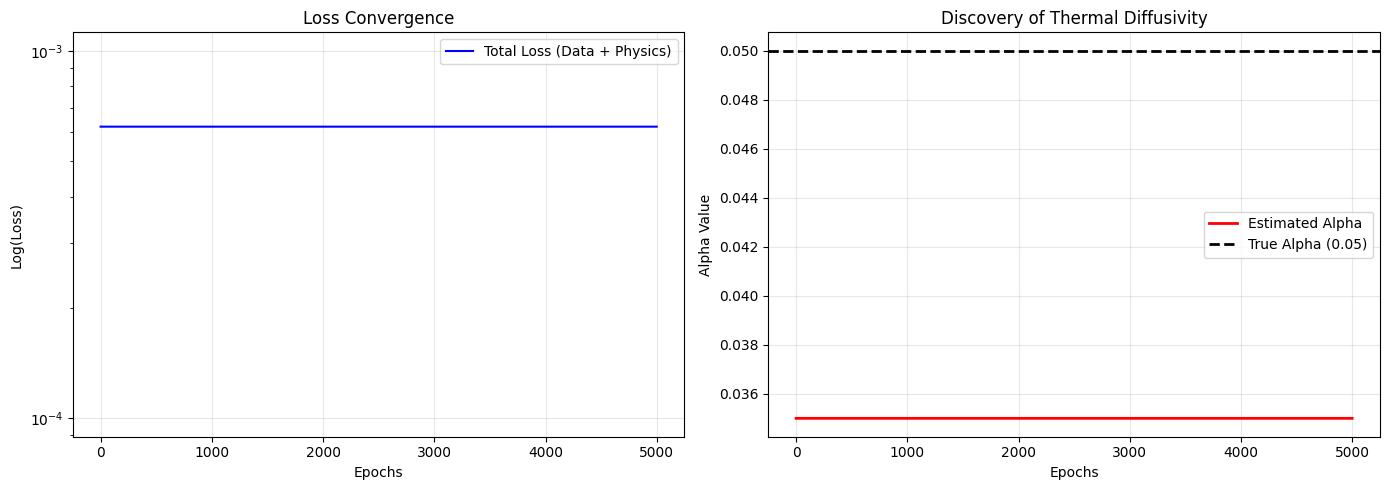

In [ ]:
import matplotlib.pyplot as plt

# Assume we know the rod's true alpha was 0.05
true_alpha = 0.05

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# --- Left Plot: Total Loss ---
ax1.plot(loss_history, color='blue', label='Total Loss (Data + Physics)')
ax1.set_yscale('log') # Log scale is standard because loss drops exponentially
ax1.set_title('Loss Convergence')
ax1.set_xlabel('Epochs')
ax1.set_ylabel('Log(Loss)')
ax1.grid(True, alpha=0.3)
ax1.legend()

# --- Right Plot: Alpha Discovery ---
ax2.plot(alpha_history, color='red', linewidth=2, label='Estimated Alpha')
ax2.axhline(y=true_alpha, color='black', linestyle='--', linewidth=2, label=f'True Alpha ({true_alpha})')

ax2.set_title('Discovery of Thermal Diffusivity')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Alpha Value')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()

Now Using Kernel

In [ ]:
import triton
import triton.language as tl

@triton.jit
def heat_equation_residual_kernel(
    u_ptr,          # Pointer to network outputs u(x,t)
    residual_ptr,   # Pointer to where we will write the loss
    alpha,          # Thermal diffusivity constant
    dx, dt,         # Grid step sizes
    nx, nt,         # Grid dimensions
    BLOCK_SIZE_X: tl.constexpr,
    BLOCK_SIZE_T: tl.constexpr
):

In [ ]:
# Get the program IDs (which block we are in)
    pid_x = tl.program_id(axis=0)
    pid_t = tl.program_id(axis=1)

    # Calculate the starting index for this block
    offsets_x = pid_x * BLOCK_SIZE_X + tl.arange(0, BLOCK_SIZE_X)
    offsets_t = pid_t * BLOCK_SIZE_T + tl.arange(0, BLOCK_SIZE_T)

    # Create a mask to prevent out-of-bounds memory access
    # (We avoid the very edges since finite differences need neighbors)
    mask_x = (offsets_x > 0) & (offsets_x < nx - 1)
    mask_t = (offsets_t < nt - 1)

In [ ]:
# Convert 2D coordinates to 1D flat memory pointers
    # Assuming row-major order: index = t * nx + x
    idx_center = offsets_t[:, None] * nx + offsets_x[None, :]
    idx_right  = offsets_t[:, None] * nx + (offsets_x[None, :] + 1)
    idx_left   = offsets_t[:, None] * nx + (offsets_x[None, :] - 1)
    idx_future = (offsets_t[:, None] + 1) * nx + offsets_x[None, :]

    # Load the data from HBM to SRAM
    u_c = tl.load(u_ptr + idx_center, mask=mask_x[None, :] & mask_t[:, None])
    u_r = tl.load(u_ptr + idx_right, mask=mask_x[None, :] & mask_t[:, None])
    u_l = tl.load(u_ptr + idx_left, mask=mask_x[None, :] & mask_t[:, None])
    u_f = tl.load(u_ptr + idx_future, mask=mask_x[None, :] & mask_t[:, None])

    # Compute derivatives entirely in fast SRAM
    u_t = (u_f - u_c) / dt
    u_xx = (u_r - 2.0 * u_c + u_l) / (dx * dx)

    # Calculate PDE residual
    residual = u_t - alpha * u_xx

    # Store the result back to HBM
    tl.store(residual_ptr + idx_center, residual, mask=mask_x[None, :] & mask_t[:, None])

In [ ]:
import torch

def compute_heat_residual(u_tensor, alpha, dx, dt, nx, nt):
    # Allocate an empty tensor on the GPU for the output
    residual_tensor = torch.zeros_like(u_tensor)

    # Define block sizes (usually powers of 2 like 16 or 32)
    BLOCK_SIZE_X = 16
    BLOCK_SIZE_T = 16

    # Calculate how many blocks we need in our Grid
    grid = (triton.cdiv(nx, BLOCK_SIZE_X), triton.cdiv(nt, BLOCK_SIZE_T))

    # Launch the kernel
    heat_equation_residual_kernel[grid](
        u_tensor, residual_tensor, alpha, dx, dt, nx, nt,
        BLOCK_SIZE_X=BLOCK_SIZE_X, BLOCK_SIZE_T=BLOCK_SIZE_T
    )

    return residual_tensor

In [ ]:
import torch

def test_heat_kernel():
    # 1. Setup grid dimensions and random data
    nx, nt = 256, 256
    dx, dt = 0.01, 0.01
    alpha = 0.5

    # Initialize random network predictions on the GPU
    u_tensor = torch.rand((nt, nx), device='cuda', dtype=torch.float32)

    # 2. PyTorch Baseline (Ground Truth)
    # Using slicing for finite differences
    u_t_pt = (u_tensor[1:, 1:-1] - u_tensor[:-1, 1:-1]) / dt
    u_xx_pt = (u_tensor[:-1, 2:] - 2.0 * u_tensor[:-1, 1:-1] + u_tensor[:-1, :-2]) / (dx * dx)
    baseline_residual = u_t_pt - alpha * u_xx_pt

    # 3. Triton Kernel Execution
    # (Assuming the compute_heat_residual function from the previous step)
    triton_residual = compute_heat_residual(u_tensor, alpha, dx, dt, nx, nt)

    # Crop the Triton output to match the interior dimensions of the baseline
    triton_interior = triton_residual[:-1, 1:-1]

    # 4. Compare
    # atol (absolute tolerance) accounts for minor floating point rounding differences
    is_correct = torch.allclose(baseline_residual, triton_interior, atol=1e-5)

    print(f"Kernel Test Passed: {is_correct}")